<a href="https://colab.research.google.com/github/kirshtalreja24/retinal-cgan-dr/blob/main/02_conditional_gan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, time, copy, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.nn.utils import spectral_norm as SN
from torchvision.utils import save_image, make_grid

PROJECT = '/content/drive/MyDrive/GenAI_Project'
for sub in ['checkpoints', 'samples', 'results', 'synthetic']:
    os.makedirs(f'{PROJECT}/{sub}', exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, torch.cuda.get_device_name(0) if device == 'cuda' else '')

Mounted at /content/drive
device: cuda Tesla T4


In [2]:
d = np.load(f'{PROJECT}/dataset/aptos_64.npz')
split = d['split']
X = d['images'][split == 'train']            # uint8 (N, 64, 64, 3)
Y = d['labels'][split == 'train']            # 0 = grade 0, 1 = grade 2, 2 = grade 4
NUM_CLASSES, Z_DIM, IMG = 3, 128, 64
CLASS_NAMES = ['Grade 0 (No DR)', 'Grade 2 (Moderate)', 'Grade 4 (Proliferative)']

X_t = torch.from_numpy(X).permute(0, 3, 1, 2).float().div(127.5).sub(1).to(device)  # [-1, 1]
Y_t = torch.from_numpy(Y).long().to(device)
class_idx = [torch.where(Y_t == c)[0] for c in range(NUM_CLASSES)]
print('train images:', len(X_t), 'per class:', [len(i) for i in class_idx])

# circular field-of-view mask (same as preprocessing) - applied to generated images
yy, xx = np.ogrid[:IMG, :IMG]; c = (IMG - 1) / 2
CIRCLE = torch.from_numpy(((yy - c) ** 2 + (xx - c) ** 2 <= (IMG / 2) ** 2).astype(np.float32)).to(device)

def sample_real(bs):
    """Class-balanced batch of real images (+ random horizontal flip = left/right eye)."""
    y = torch.randint(0, NUM_CLASSES, (bs,), device=device)
    idx = torch.empty(bs, dtype=torch.long, device=device)
    for k in range(NUM_CLASSES):
        m = y == k
        pool = class_idx[k]
        idx[m] = pool[torch.randint(len(pool), (int(m.sum()),), device=device)]
    x = X_t[idx]
    flip = torch.rand(bs, device=device) < 0.5
    x[flip] = x[flip].flip(3)
    return x, y

train images: 2169 per class: [1263, 699, 207]


In [3]:
def rand_brightness(x):
    return x + (torch.rand(x.size(0), 1, 1, 1, device=x.device) - 0.5)

def rand_saturation(x):
    m = x.mean(dim=1, keepdim=True)
    return (x - m) * (torch.rand(x.size(0), 1, 1, 1, device=x.device) * 2) + m

def rand_contrast(x):
    m = x.mean(dim=[1, 2, 3], keepdim=True)
    return (x - m) * (torch.rand(x.size(0), 1, 1, 1, device=x.device) + 0.5) + m

def rand_translation(x, ratio=0.125):
    B, C, H, W = x.shape
    sx, sy = int(H * ratio + 0.5), int(W * ratio + 0.5)
    tx = torch.randint(-sx, sx + 1, (B, 1, 1), device=x.device)
    ty = torch.randint(-sy, sy + 1, (B, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=x.device), torch.arange(H, device=x.device),
                                torch.arange(W, device=x.device), indexing='ij')
    gx = torch.clamp(gx + tx + 1, 0, H + 1)
    gy = torch.clamp(gy + ty + 1, 0, W + 1)
    xp = F.pad(x, [1, 1, 1, 1, 0, 0, 0, 0])
    return xp.permute(0, 2, 3, 1).contiguous()[gb, gx, gy].permute(0, 3, 1, 2)

def rand_cutout(x, ratio=0.5):
    B, C, H, W = x.shape
    ch, cw = int(H * ratio + 0.5), int(W * ratio + 0.5)
    ox = torch.randint(0, H + (1 - ch % 2), (B, 1, 1), device=x.device)
    oy = torch.randint(0, W + (1 - cw % 2), (B, 1, 1), device=x.device)
    gb, gx, gy = torch.meshgrid(torch.arange(B, device=x.device), torch.arange(ch, device=x.device),
                                torch.arange(cw, device=x.device), indexing='ij')
    gx = torch.clamp(gx + ox - ch // 2, 0, H - 1)
    gy = torch.clamp(gy + oy - cw // 2, 0, W - 1)
    mask = torch.ones(B, H, W, dtype=x.dtype, device=x.device)
    mask[gb, gx, gy] = 0
    return x * mask.unsqueeze(1)

def diff_augment(x):
    for f in (rand_brightness, rand_saturation, rand_contrast, rand_translation, rand_cutout):
        x = f(x)
    return x

In [4]:
class CondBN(nn.Module):
    """BatchNorm whose scale/shift depend on the class label."""
    def __init__(self, ch, n_classes):
        super().__init__()
        self.bn = nn.BatchNorm2d(ch, affine=False)
        self.gamma = nn.Embedding(n_classes, ch)
        self.beta = nn.Embedding(n_classes, ch)
        nn.init.ones_(self.gamma.weight); nn.init.zeros_(self.beta.weight)
    def forward(self, x, y):
        return self.bn(x) * self.gamma(y)[:, :, None, None] + self.beta(y)[:, :, None, None]

class GBlock(nn.Module):
    def __init__(self, cin, cout, n_classes):
        super().__init__()
        self.bn = CondBN(cin, n_classes)
        self.conv = nn.Conv2d(cin, cout, 3, 1, 1)
    def forward(self, x, y):
        x = F.interpolate(F.relu(self.bn(x, y)), scale_factor=2, mode='nearest')
        return self.conv(x)

class Generator(nn.Module):
    def __init__(self, z_dim=Z_DIM, n_classes=NUM_CLASSES, ch=64):
        super().__init__()
        self.ch = ch
        self.embed = nn.Embedding(n_classes, z_dim)               # label embedding
        self.fc = nn.Linear(2 * z_dim, 4 * 4 * ch * 8)             # [z, embed(y)] -> 4x4
        self.blocks = nn.ModuleList([
            GBlock(ch * 8, ch * 4, n_classes),   # 4  -> 8
            GBlock(ch * 4, ch * 2, n_classes),   # 8  -> 16
            GBlock(ch * 2, ch,     n_classes),   # 16 -> 32
            GBlock(ch,     ch,     n_classes)])  # 32 -> 64
        self.bn_out = nn.BatchNorm2d(ch)
        self.out = nn.Conv2d(ch, 3, 3, 1, 1)
    def forward(self, z, y):
        h = self.fc(torch.cat([z, self.embed(y)], 1)).view(-1, self.ch * 8, 4, 4)
        for b in self.blocks:
            h = b(h, y)
        return torch.tanh(self.out(F.relu(self.bn_out(h))))

class Discriminator(nn.Module):
    def __init__(self, n_classes=NUM_CLASSES, ch=64):
        super().__init__()
        def block(cin, cout):
            return [SN(nn.Conv2d(cin, cout, 3, 1, 1)), nn.LeakyReLU(0.2),
                    SN(nn.Conv2d(cout, cout, 4, 2, 1)), nn.LeakyReLU(0.2)]
        self.net = nn.Sequential(*block(3, ch), *block(ch, ch * 2),          # 64 -> 32 -> 16
                                 *block(ch * 2, ch * 4), *block(ch * 4, ch * 8))  # 16 -> 8 -> 4
        self.linear = SN(nn.Linear(ch * 8, 1))
        self.embed = SN(nn.Embedding(n_classes, ch * 8))          # projection term
    def forward(self, x, y):
        h = self.net(x).sum(dim=[2, 3])
        return self.linear(h).squeeze(1) + (self.embed(y) * h).sum(1)

G, D = Generator().to(device), Discriminator().to(device)
print('G params: %.2fM  D params: %.2fM' % (sum(p.numel() for p in G.parameters()) / 1e6,
                                           sum(p.numel() for p in D.parameters()) / 1e6))

G params: 3.70M  D params: 7.12M


In [5]:
TOTAL_ITERS = 20000      # ~30-45 min on a T4. Can be raised later and resumed.
BATCH = 64
LR_G, LR_D, BETAS = 1e-4, 4e-4, (0.0, 0.9)   # two time-scale update rule
EMA_DECAY = 0.999
CKPT = f'{PROJECT}/checkpoints/cgan_last.pt'

G_ema = copy.deepcopy(G).eval()
for p in G_ema.parameters():
    p.requires_grad_(False)
optG = torch.optim.Adam(G.parameters(), lr=LR_G, betas=BETAS)
optD = torch.optim.Adam(D.parameters(), lr=LR_D, betas=BETAS)

@torch.no_grad()
def ema_update():
    for pe, p in zip(G_ema.parameters(), G.parameters()):
        pe.lerp_(p, 1 - EMA_DECAY)
    for be, b in zip(G_ema.buffers(), G.buffers()):
        be.copy_(b)

def save_ckpt(it, history):
    torch.save({'it': it, 'G': G.state_dict(), 'D': D.state_dict(), 'G_ema': G_ema.state_dict(),
                'optG': optG.state_dict(), 'optD': optD.state_dict(), 'history': history}, CKPT + '.tmp')
    os.replace(CKPT + '.tmp', CKPT)          # atomic: never leaves a half-written file

start_it, history = 0, {'it': [], 'loss_D': [], 'loss_G': [], 'D_real': [], 'D_fake': []}
if os.path.exists(CKPT):
    ck = torch.load(CKPT, map_location=device)
    G.load_state_dict(ck['G']); D.load_state_dict(ck['D']); G_ema.load_state_dict(ck['G_ema'])
    optG.load_state_dict(ck['optG']); optD.load_state_dict(ck['optD'])
    start_it, history = ck['it'], ck['history']
    print('Resumed from iteration', start_it)
else:
    print('Starting from scratch')

# fixed noise -> the same 8 samples per class in every progress grid
fixed_z = torch.randn(24, Z_DIM, generator=torch.Generator().manual_seed(0)).to(device)
fixed_y = torch.arange(NUM_CLASSES).repeat_interleave(8).to(device)

def show_grid(gen, path=None, title=''):
    with torch.no_grad():
        x = gen(fixed_z, fixed_y) * CIRCLE
    grid = make_grid(x * 0.5 + 0.5, nrow=8, padding=2).clamp(0, 1)
    if path:
        save_image(grid, path)
    plt.figure(figsize=(12, 4.8)); plt.imshow(grid.permute(1, 2, 0).cpu()); plt.axis('off')
    plt.title(title + '   rows: grade 0 / grade 2 / grade 4'); plt.show()

Starting from scratch


it    500 | loss_D 2.051 loss_G 0.051 | D(real) +0.02 D(fake) +0.07 | 3.2 it/s
it   1000 | loss_D 1.543 loss_G 0.346 | D(real) -0.04 D(fake) -0.50 | 3.2 it/s


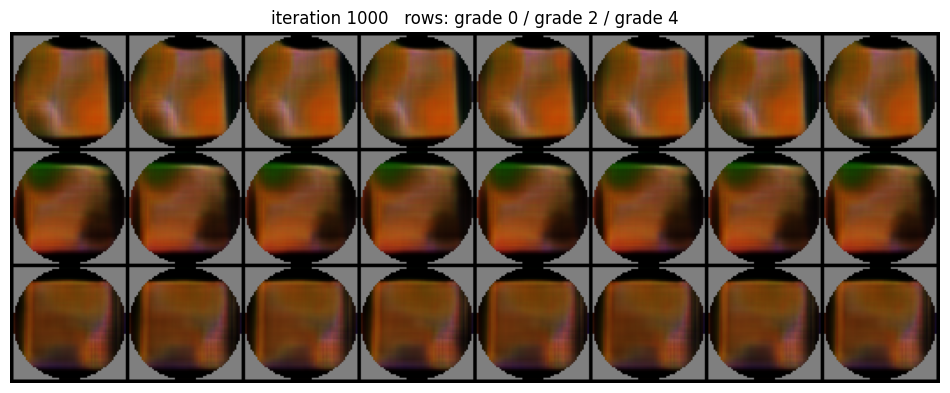

it   1500 | loss_D 1.980 loss_G 0.233 | D(real) -0.21 D(fake) -0.23 | 3.2 it/s
it   2000 | loss_D 2.079 loss_G 0.096 | D(real) -0.18 D(fake) -0.10 | 3.2 it/s


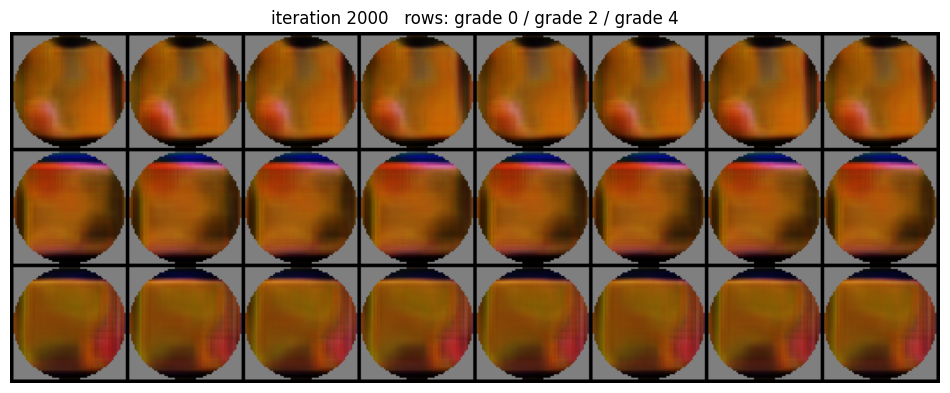

it   2500 | loss_D 1.916 loss_G -0.038 | D(real) +0.07 D(fake) -0.02 | 3.2 it/s
it   3000 | loss_D 1.924 loss_G 0.375 | D(real) -0.12 D(fake) -0.19 | 3.3 it/s


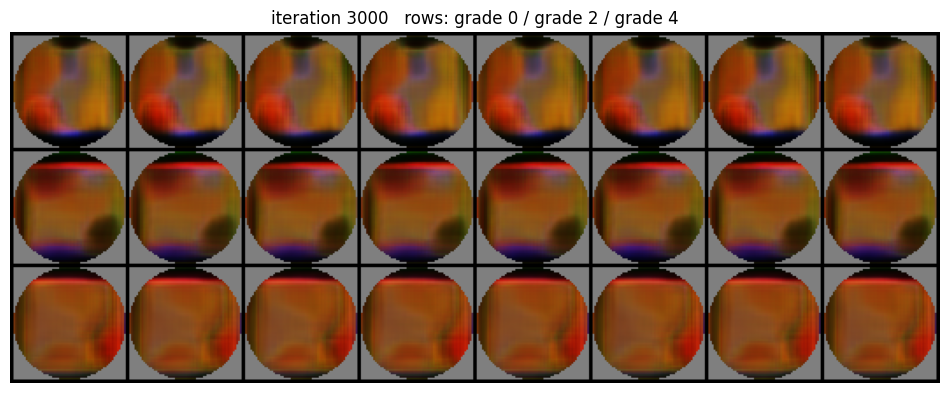

it   3500 | loss_D 2.003 loss_G 0.261 | D(real) -0.24 D(fake) -0.24 | 3.2 it/s
it   4000 | loss_D 1.978 loss_G -0.266 | D(real) +0.14 D(fake) +0.12 | 3.3 it/s


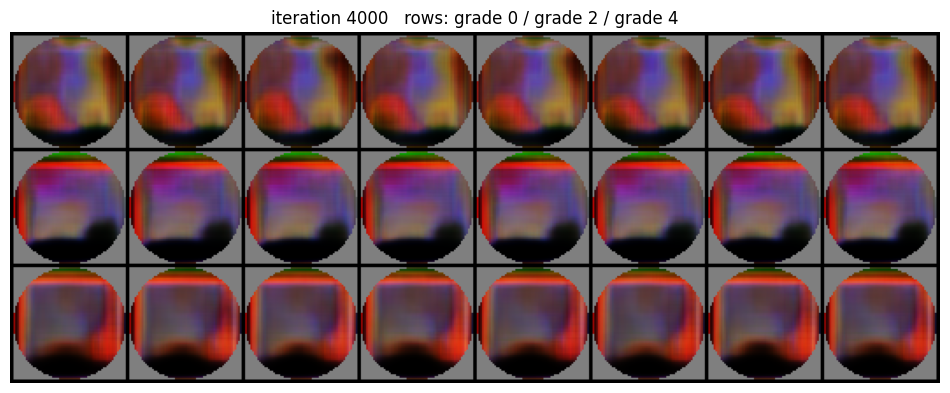

it   4500 | loss_D 2.060 loss_G 0.114 | D(real) +0.04 D(fake) +0.10 | 3.3 it/s
it   5000 | loss_D 2.083 loss_G 0.020 | D(real) -0.20 D(fake) -0.12 | 3.3 it/s


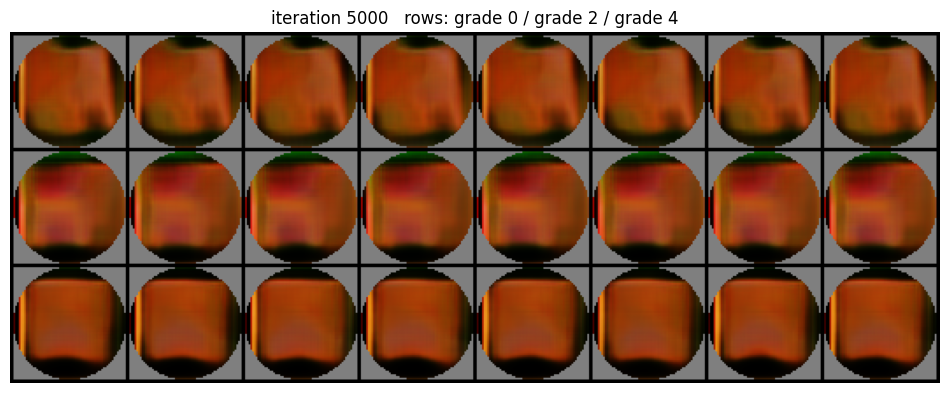

it   5500 | loss_D 1.872 loss_G 0.316 | D(real) -0.21 D(fake) -0.34 | 3.3 it/s
it   6000 | loss_D 1.936 loss_G -0.061 | D(real) -0.05 D(fake) -0.11 | 3.3 it/s


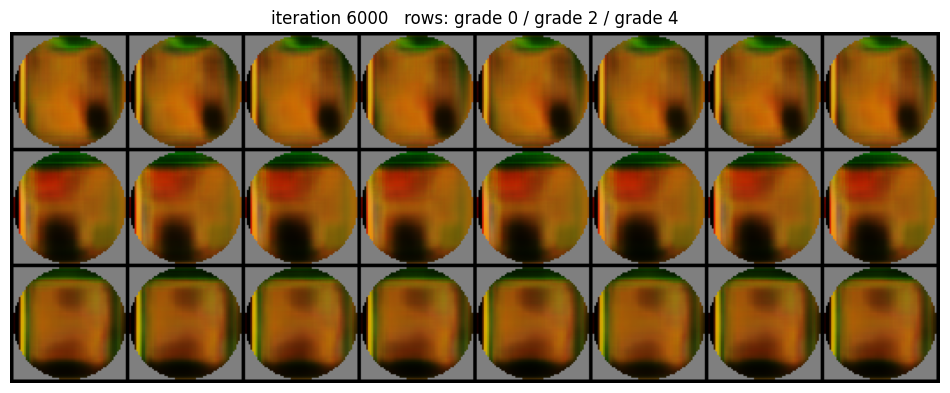

it   6500 | loss_D 2.181 loss_G 0.118 | D(real) -0.20 D(fake) -0.02 | 3.3 it/s
it   7000 | loss_D 2.062 loss_G -0.030 | D(real) -0.07 D(fake) -0.01 | 3.3 it/s


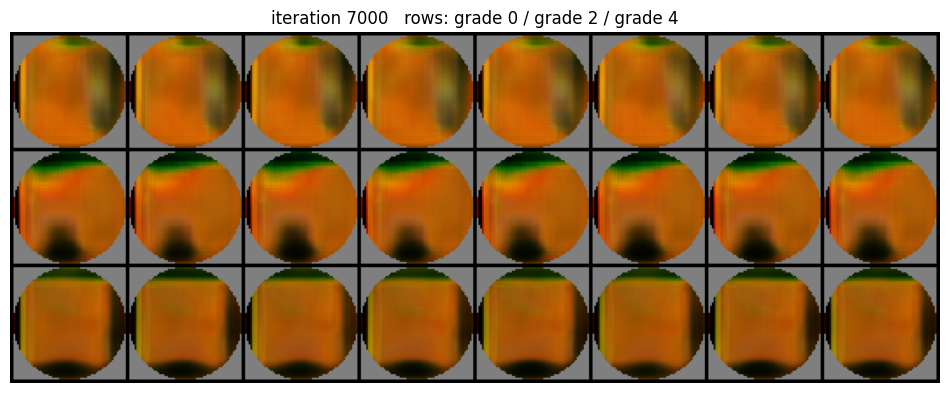

it   7500 | loss_D 2.148 loss_G -0.076 | D(real) +0.03 D(fake) +0.18 | 3.3 it/s
it   8000 | loss_D 2.095 loss_G -0.160 | D(real) +0.04 D(fake) +0.13 | 3.3 it/s


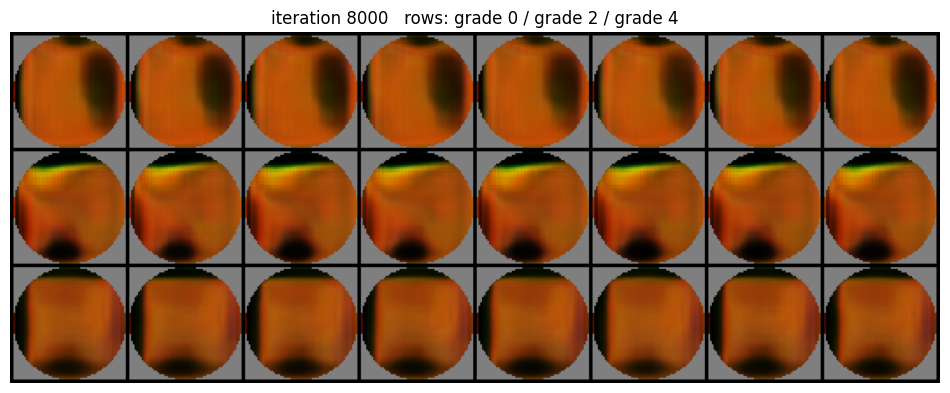

it   8500 | loss_D 2.034 loss_G -0.079 | D(real) +0.01 D(fake) +0.04 | 3.3 it/s
it   9000 | loss_D 1.948 loss_G -0.492 | D(real) +0.10 D(fake) +0.04 | 3.3 it/s


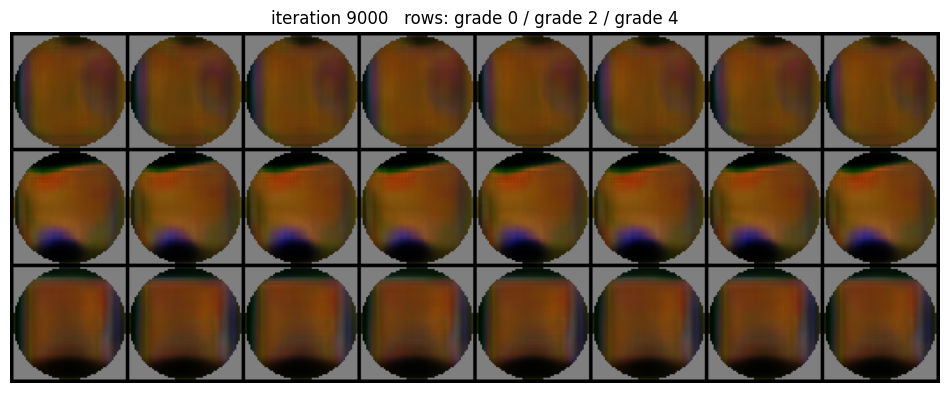

it   9500 | loss_D 2.168 loss_G 0.115 | D(real) -0.29 D(fake) -0.12 | 3.3 it/s
it  10000 | loss_D 2.025 loss_G 0.006 | D(real) -0.08 D(fake) -0.06 | 3.3 it/s


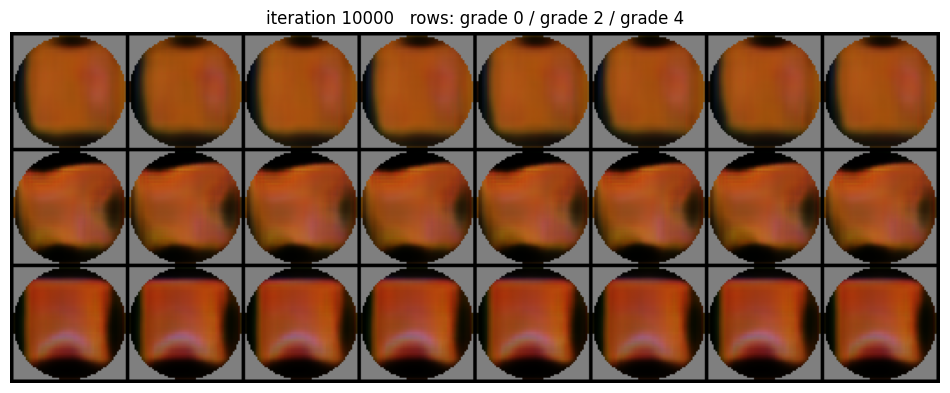

it  10500 | loss_D 2.075 loss_G -0.200 | D(real) +0.15 D(fake) +0.23 | 3.3 it/s
it  11000 | loss_D 1.985 loss_G 0.091 | D(real) -0.08 D(fake) -0.09 | 3.3 it/s


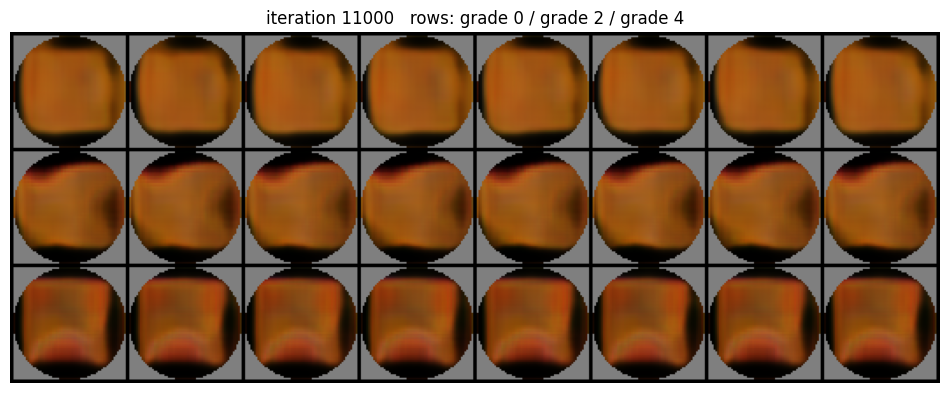

it  11500 | loss_D 2.170 loss_G -0.222 | D(real) +0.32 D(fake) +0.48 | 3.3 it/s
it  12000 | loss_D 1.960 loss_G 0.032 | D(real) +0.05 D(fake) +0.01 | 3.3 it/s


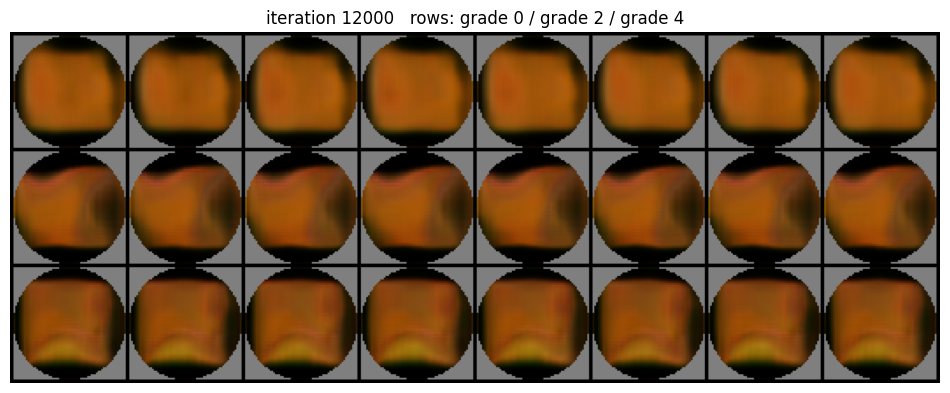

it  12500 | loss_D 2.023 loss_G 0.010 | D(real) +0.03 D(fake) +0.05 | 3.3 it/s
it  13000 | loss_D 2.011 loss_G 0.008 | D(real) +0.07 D(fake) +0.08 | 3.3 it/s


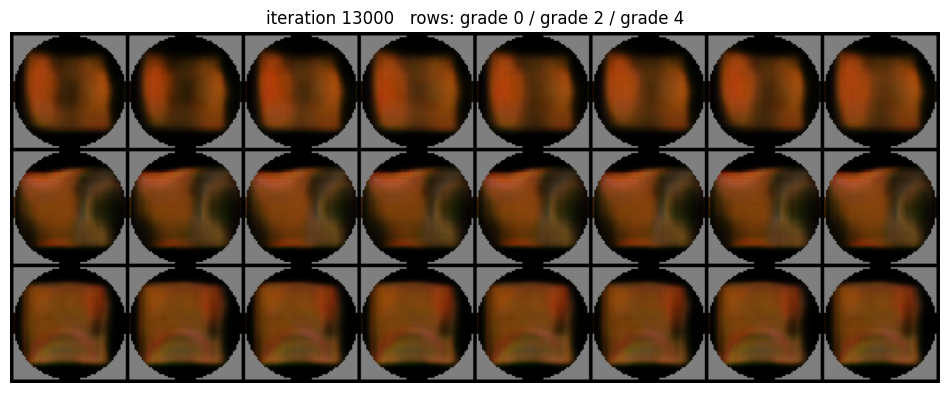

it  13500 | loss_D 1.785 loss_G -0.161 | D(real) +0.22 D(fake) +0.01 | 3.3 it/s
it  14000 | loss_D 1.988 loss_G -0.114 | D(real) -0.04 D(fake) -0.05 | 3.3 it/s


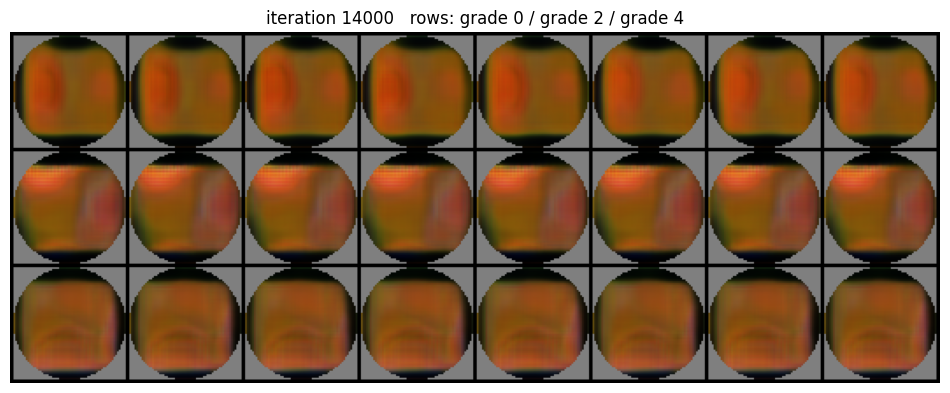

it  14500 | loss_D 1.897 loss_G 0.200 | D(real) -0.11 D(fake) -0.22 | 3.3 it/s
it  15000 | loss_D 1.931 loss_G 0.125 | D(real) -0.03 D(fake) -0.10 | 3.3 it/s


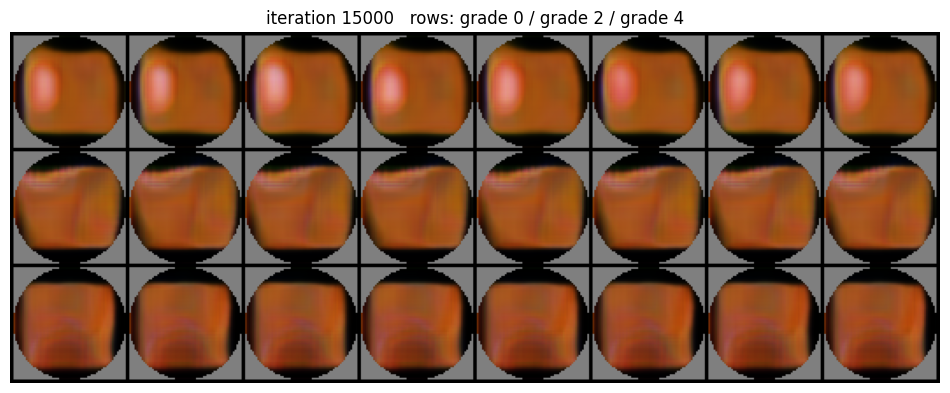

it  15500 | loss_D 2.023 loss_G -0.315 | D(real) +0.19 D(fake) +0.21 | 3.3 it/s
it  16000 | loss_D 1.943 loss_G -0.129 | D(real) +0.20 D(fake) +0.14 | 3.3 it/s


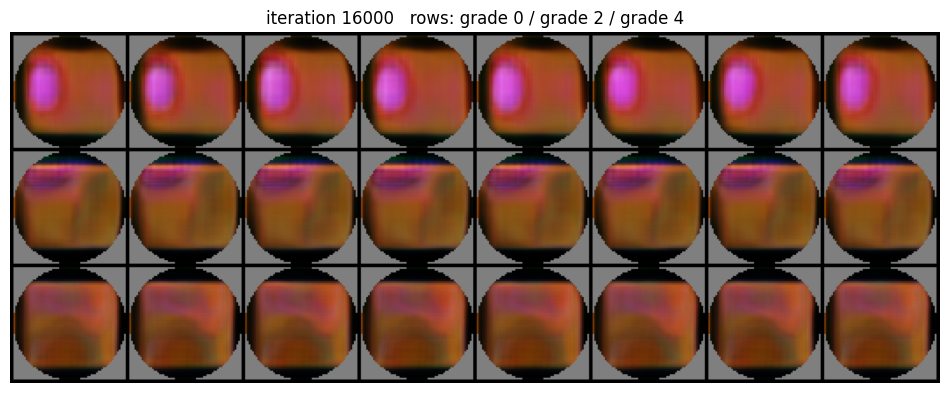

it  16500 | loss_D 1.964 loss_G 0.026 | D(real) -0.00 D(fake) -0.04 | 3.3 it/s
it  17000 | loss_D 2.077 loss_G 0.166 | D(real) -0.09 D(fake) -0.01 | 3.3 it/s


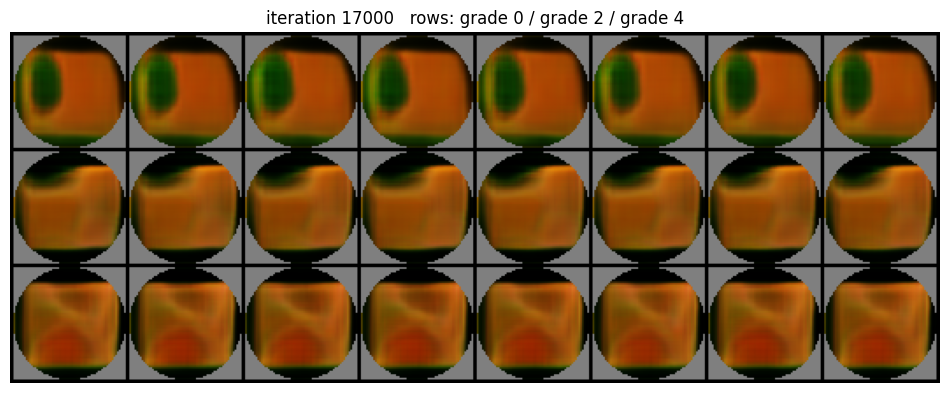

it  17500 | loss_D 1.955 loss_G 0.254 | D(real) -0.20 D(fake) -0.24 | 3.3 it/s
it  18000 | loss_D 1.995 loss_G 0.242 | D(real) -0.22 D(fake) -0.22 | 3.3 it/s


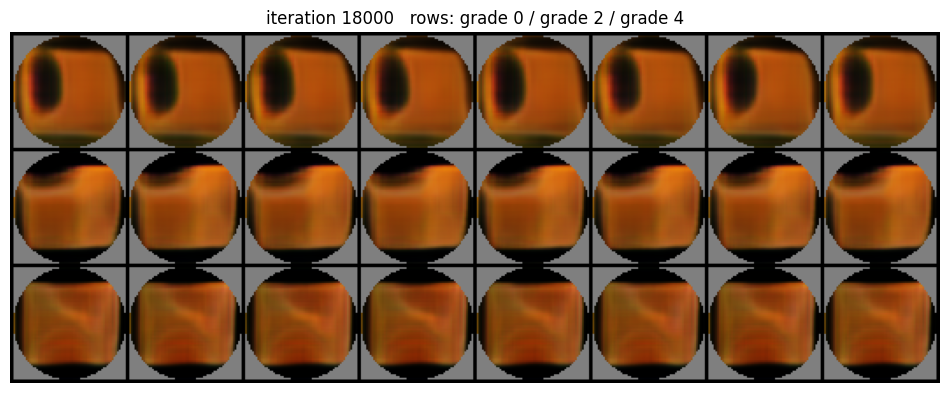

it  18500 | loss_D 1.955 loss_G 0.027 | D(real) -0.07 D(fake) -0.11 | 3.3 it/s
it  19000 | loss_D 2.139 loss_G -0.192 | D(real) +0.33 D(fake) +0.47 | 3.3 it/s


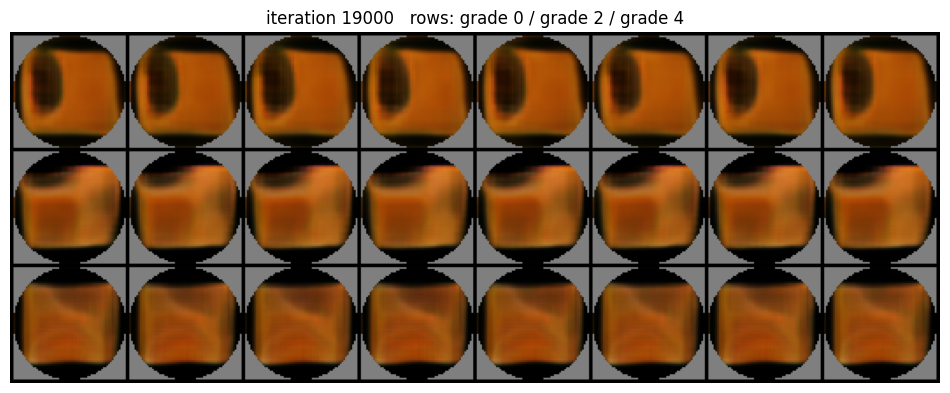

it  19500 | loss_D 2.138 loss_G 0.251 | D(real) -0.13 D(fake) +0.01 | 3.3 it/s
it  20000 | loss_D 2.056 loss_G 0.087 | D(real) +0.02 D(fake) +0.08 | 3.3 it/s


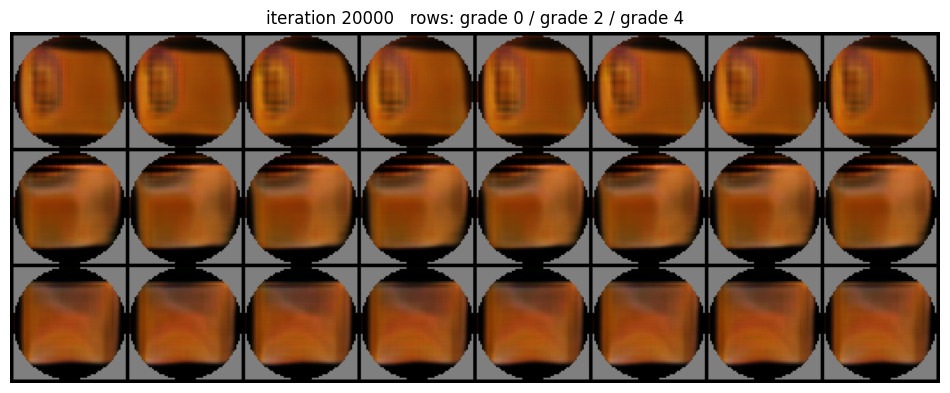

Training finished at iteration 20000


In [7]:
G.train(); D.train()
it, t0 = start_it, time.time()
while it < TOTAL_ITERS:
    # ---- Discriminator step (hinge loss) ----
    real, y_real = sample_real(BATCH)
    z = torch.randn(BATCH, Z_DIM, device=device)
    y_fake = torch.randint(0, NUM_CLASSES, (BATCH,), device=device)
    with torch.no_grad():
        fake = G(z, y_fake)
    d_real = D(diff_augment(real), y_real)
    d_fake = D(diff_augment(fake), y_fake)
    loss_D = F.relu(1 - d_real).mean() + F.relu(1 + d_fake).mean()
    optD.zero_grad(set_to_none=True); loss_D.backward(); optD.step()

    # ---- Generator step ----
    z = torch.randn(BATCH, Z_DIM, device=device)
    y_fake = torch.randint(0, NUM_CLASSES, (BATCH,), device=device)
    loss_G = -D(diff_augment(G(z, y_fake)), y_fake).mean()
    optG.zero_grad(set_to_none=True); loss_G.backward(); optG.step()

    ema_update()
    it += 1

    if it % 100 == 0:
        for k, v in (('it', it), ('loss_D', loss_D.item()), ('loss_G', loss_G.item()),
                     ('D_real', d_real.mean().item()), ('D_fake', d_fake.mean().item())):
            history[k].append(v)
    if it % 500 == 0:
        print(f'it {it:6d} | loss_D {loss_D.item():.3f} loss_G {loss_G.item():.3f} | '
              f'D(real) {d_real.mean().item():+.2f} D(fake) {d_fake.mean().item():+.2f} | '
              f'{(it - start_it) / (time.time() - t0):.1f} it/s')
    if it % 1000 == 0:
        save_ckpt(it, history)
        show_grid(G_ema, f'{PROJECT}/samples/cgan_it{it:06d}.png', f'iteration {it}')
    if it % 5000 == 0:
        torch.save(G_ema.state_dict(), f'{PROJECT}/checkpoints/cgan_G_ema_it{it:06d}.pt')

save_ckpt(it, history)
torch.save(G_ema.state_dict(), f'{PROJECT}/checkpoints/cgan_G_ema_final.pt')
print('Training finished at iteration', it)

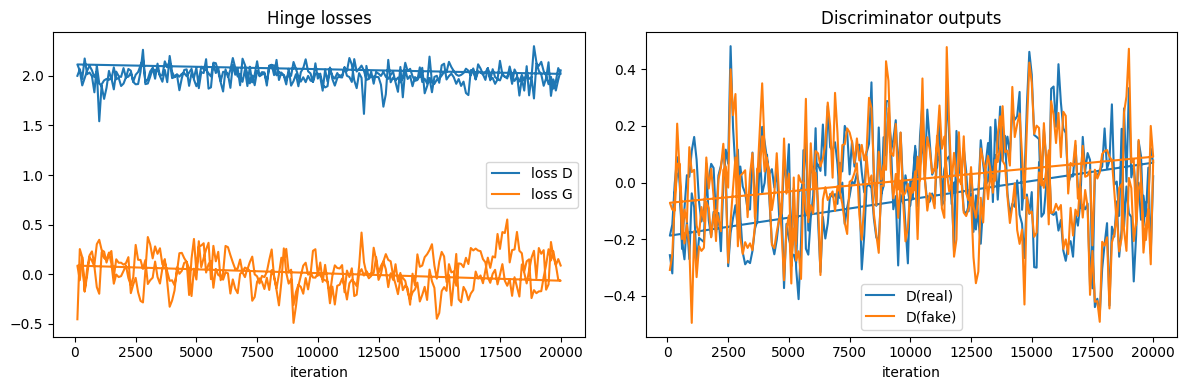

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history['it'], history['loss_D'], label='loss D')
ax[0].plot(history['it'], history['loss_G'], label='loss G')
ax[0].set_xlabel('iteration'); ax[0].set_title('Hinge losses'); ax[0].legend()
ax[1].plot(history['it'], history['D_real'], label='D(real)')
ax[1].plot(history['it'], history['D_fake'], label='D(fake)')
ax[1].set_xlabel('iteration'); ax[1].set_title('Discriminator outputs'); ax[1].legend()
plt.tight_layout(); plt.savefig(f'{PROJECT}/results/cgan_losses.png', dpi=150); plt.show()

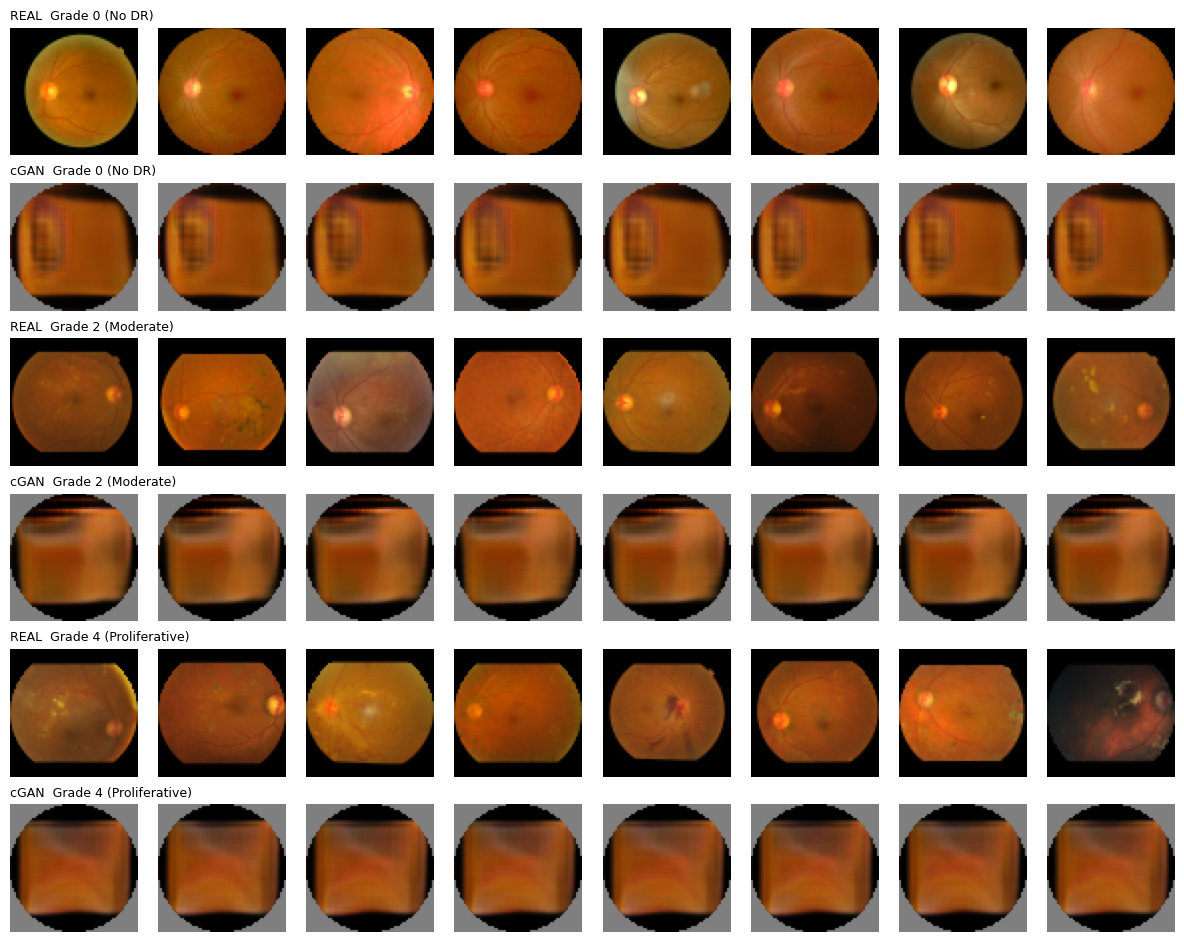

In [9]:
G_ema.eval()
rng = np.random.default_rng(1)
fig, axes = plt.subplots(6, 8, figsize=(12, 9.5))
with torch.no_grad():
    for k in range(NUM_CLASSES):
        real_ids = rng.choice(class_idx[k].cpu().numpy(), 8, replace=False)
        z = torch.randn(8, Z_DIM, device=device)
        fake = (G_ema(z, torch.full((8,), k, device=device)) * CIRCLE * 0.5 + 0.5).clamp(0, 1)
        for j in range(8):
            axes[2 * k, j].imshow(X[real_ids[j]])
            axes[2 * k + 1, j].imshow(fake[j].permute(1, 2, 0).cpu())
            axes[2 * k, j].axis('off'); axes[2 * k + 1, j].axis('off')
        axes[2 * k, 0].set_title(f'REAL  {CLASS_NAMES[k]}', loc='left', fontsize=9)
        axes[2 * k + 1, 0].set_title(f'cGAN  {CLASS_NAMES[k]}', loc='left', fontsize=9)
plt.tight_layout(); plt.savefig(f'{PROJECT}/results/cgan_real_vs_fake.png', dpi=150); plt.show()

In [10]:
@torch.no_grad()
def generate(gen, n_per_class, seed, batch=250):
    g = torch.Generator(device=device).manual_seed(seed)
    imgs, labs = [], []
    for k in range(NUM_CLASSES):
        for s in range(0, n_per_class, batch):
            n = min(batch, n_per_class - s)
            z = torch.randn(n, Z_DIM, device=device, generator=g)
            x = gen(z, torch.full((n,), k, device=device)) * CIRCLE      # same FOV mask as real
            x = ((x * 0.5 + 0.5).clamp(0, 1) * 255).round().byte()
            imgs.append(x.permute(0, 2, 3, 1).cpu().numpy()); labs.append(np.full(n, k))
    return np.concatenate(imgs), np.concatenate(labs)

for seed in [0, 1, 2]:
    xs, ys = generate(G_ema, 1000, seed)
    np.savez_compressed(f'{PROJECT}/synthetic/cgan_seed{seed}.npz', images=xs, labels=ys)
    print('seed', seed, xs.shape, np.bincount(ys))
print(os.listdir(f'{PROJECT}/synthetic'))

seed 0 (3000, 64, 64, 3) [1000 1000 1000]
seed 1 (3000, 64, 64, 3) [1000 1000 1000]
seed 2 (3000, 64, 64, 3) [1000 1000 1000]
['cgan_seed0.npz', 'cgan_seed1.npz', 'cgan_seed2.npz']
